# Transformada de Fourier 2D

Referencias:

* [Eliminación de ruido en imágenes mediante FFT](https://scipy-lectures.org/intro/scipy/auto_examples/solutions/plot_fft_image_denoise.html) de Scipy lecture notes

* [Procesamiento digital de imágenes usando la Transformada de Fourier en Python](https://hicraigchen.medium.com/digital-image-processing-using-fourier-transform-in-python-bcb49424fd82) de Craig Chen

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from   matplotlib.colors import LogNorm
from   scipy.fftpack     import fft2,ifft2,fftshift,ifftshift
from   scipy.ndimage     import gaussian_filter
from   scipy.signal      import fftconvolve

In [23]:
!wget https://www.dropbox.com/scl/fi/qkdq3ie06agqqb7uod3wb/moonlanding.png?rlkey=ks21d42cungm2w8co7q9i7l5i&st=zxbgllju&dl=0
!mv 'moonlanding.png?rlkey=ks21d42cungm2w8co7q9i7l5i' 'moonlanding.png'

--2026-06-24 00:40:41--  https://www.dropbox.com/scl/fi/qkdq3ie06agqqb7uod3wb/moonlanding.png?rlkey=ks21d42cungm2w8co7q9i7l5i
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://ucefaa6fdc4b23bf9b34ef6eb44e.dl.dropboxusercontent.com/cd/0/inline/DC8O5Gwx0xVRdt0CvKSv4-AFXgLCr1KyaQsjdsj1NMl0UzVUlJ1bfmWrUYZfdhas6sAXouFZ2FQmX_Jhgz9uMjbtb_qEZULCfg-pArJV6oalATpVmEAteViM58DQpFUnXSs/file# [following]
--2026-06-24 00:40:42--  https://ucefaa6fdc4b23bf9b34ef6eb44e.dl.dropboxusercontent.com/cd/0/inline/DC8O5Gwx0xVRdt0CvKSv4-AFXgLCr1KyaQsjdsj1NMl0UzVUlJ1bfmWrUYZfdhas6sAXouFZ2FQmX_Jhgz9uMjbtb_qEZULCfg-pArJV6oalATpVmEAteViM58DQpFUnXSs/file
Resolving ucefaa6fdc4b23bf9b34ef6eb44e.dl.dropboxusercontent.com (ucefaa6fdc4b23bf9b34ef6eb44e.dl.dropboxusercontent.com)... 162.125.5.15, 2620:100:601d:15::a27d:50f
Connecting to ucef

# Imágenes usadas en nuestros ejemplos

In [2]:
!wget https://www.dropbox.com/scl/fi/9owh126z26arlsrjbuy9b/chiloe.png?rlkey=glicqp6vlbdo5ot93b7fi49k2&st=bhng376j&dl=0
!mv chiloe.png?rlkey=glicqp6vlbdo5ot93b7fi49k2 chiloe.png
!wget https://www.dropbox.com/scl/fi/qkdq3ie06agqqb7uod3wb/moonlanding.png?rlkey=ks21d42cungm2w8co7q9i7l5i&st=zxbgllju&dl=0
!mv 'moonlanding.png?rlkey=ks21d42cungm2w8co7q9i7l5i' 'moonlanding.png'
!wget https://www.dropbox.com/scl/fi/96rw3supl4dbo404ctazj/barbara.png?rlkey=0v06zk7o13u3scowg5c4bj1x0
!mv 'barbara.png?rlkey=0v06zk7o13u3scowg5c4bj1x0' 'barbara.png'
!wget https://www.dropbox.com/scl/fi/922xq9dhk4sclcjy6zhb2/elephant.png?rlkey=9cn9hv1x8desf7cnofuyfd6f7
!mv 'elephant.png?rlkey=9cn9hv1x8desf7cnofuyfd6f7' 'elephant.png'

--2026-06-24 00:39:08--  https://www.dropbox.com/scl/fi/9owh126z26arlsrjbuy9b/chiloe.png?rlkey=glicqp6vlbdo5ot93b7fi49k2
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc55e1ca9e3abc973ad27464c0fe.dl.dropboxusercontent.com/cd/0/inline/DC8RPT-CjiEYKpjDfakzK_hZ8Gpzgd9gv3TbEq-OKwBd8lC-_hTTelRhMmDSPrfAsyj5ynXvOgiepQsbd6DY8IeR5JQz1cOJQAoogtmrJA-I3Xboe92gIiV8abe6mXSBng4/file# [following]
--2026-06-24 00:39:08--  https://uc55e1ca9e3abc973ad27464c0fe.dl.dropboxusercontent.com/cd/0/inline/DC8RPT-CjiEYKpjDfakzK_hZ8Gpzgd9gv3TbEq-OKwBd8lC-_hTTelRhMmDSPrfAsyj5ynXvOgiepQsbd6DY8IeR5JQz1cOJQAoogtmrJA-I3Xboe92gIiV8abe6mXSBng4/file
Resolving uc55e1ca9e3abc973ad27464c0fe.dl.dropboxusercontent.com (uc55e1ca9e3abc973ad27464c0fe.dl.dropboxusercontent.com)... 162.125.5.15, 2620:100:601d:15::a27d:50f
Connecting to uc55e1ca9

# Funciones básicas




## Leer la imagen de entrada

In [3]:
X = cv2.imread("chiloe.png", 0)


## Funciones de visualización

In [4]:
def surface_plot (matrix, **kwargs):
    # obtener las matrices de coordenadas cartesianas a partir de la matriz
    # x son columnas, y son filas
    (x, y) = np.meshgrid(np.arange(matrix.shape[1]), np.arange(matrix.shape[0]))
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    surf = ax.plot_surface(x, y, matrix, **kwargs)
    return (fig, ax, surf)

def plot_spectrum(X_ft,centered=True):
    # Un mapa de color logarítmico
    if centered:
      X_ftc = fftshift(X_ft)
    else:
      X_ftc = X_ft
    plt.imshow(np.abs(X_ftc), norm=LogNorm(vmin=5))
    plt.colorbar()


## Transformada directa: fftshift, inversa

original > Fourier > original (sin filtrado)

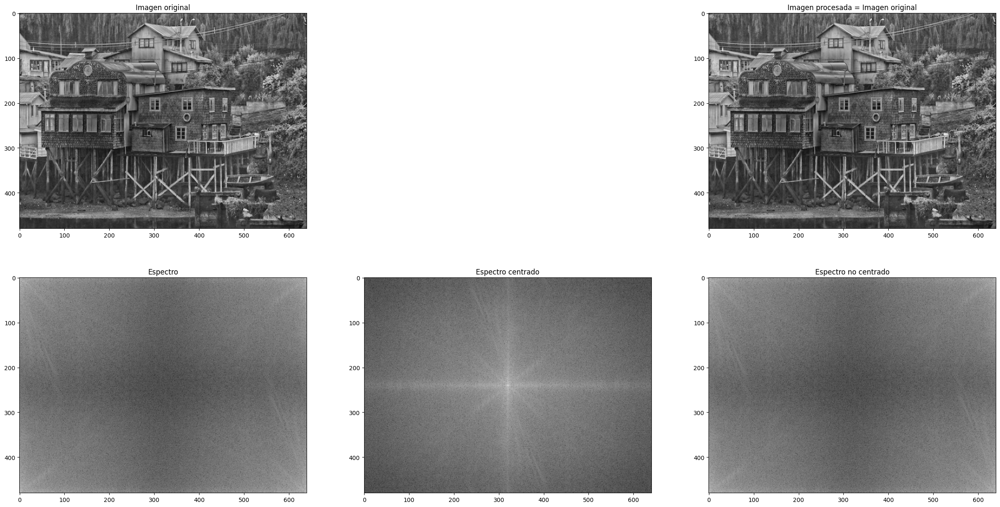

In [5]:
# La imagen original se transforma (directa e inversa)

plt.figure(figsize=(30,15))

plt.subplot(231), plt.imshow(X, "gray"), plt.title("Imagen original")

X_ft = fft2(X)
plt.subplot(234), plt.imshow(np.log(1+np.abs(X_ft)), "gray"), plt.title("Espectro")

X_ftc = fftshift(X_ft)
plt.subplot(235), plt.imshow(np.log(1+np.abs(X_ftc)), "gray"), plt.title("Espectro centrado")

X_ft_inv = ifftshift(X_ftc)
plt.subplot(236), plt.imshow(np.log(1+np.abs(X_ft_inv)), "gray"), plt.title("Espectro no centrado")

X_new = ifft2(X_ft_inv)
plt.subplot(233), plt.imshow(np.abs(X_new), "gray"), plt.title("Imagen procesada = Imagen original")

plt.show()

## Representación en color

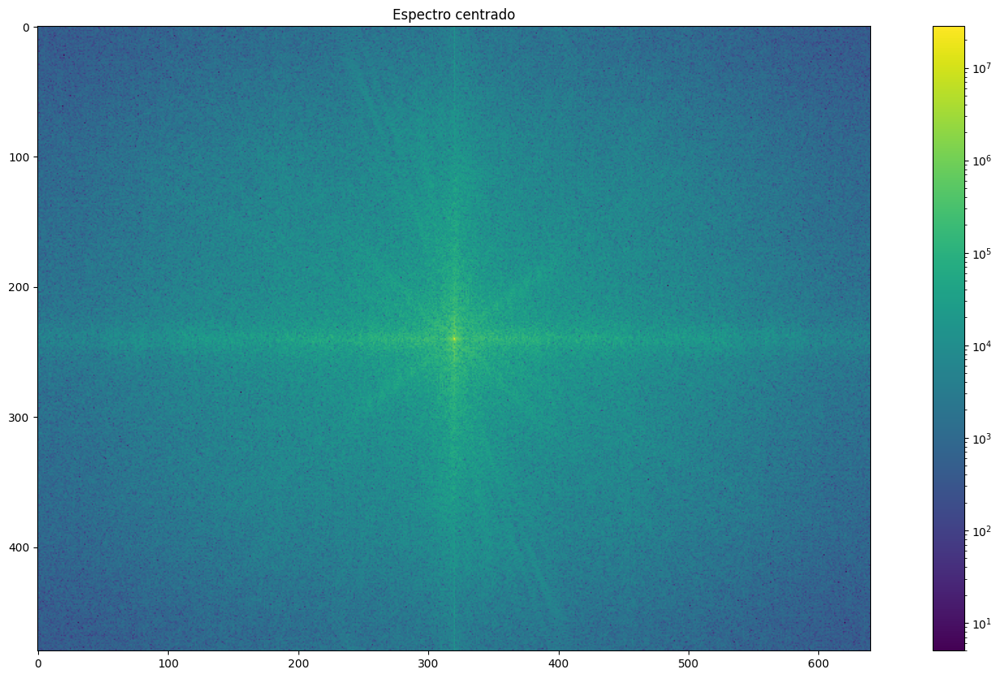

In [6]:
plt.figure(figsize=(20,10))
plot_spectrum(X_ft)
plt.title('Espectro centrado')
plt.show()

## Módulo y fase del espectro

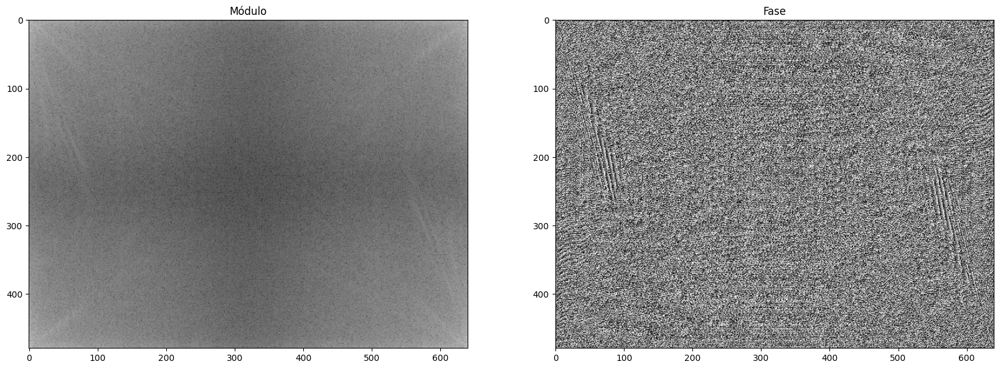

In [7]:
plt.figure(figsize=(20,8))

plt.subplot(121), plt.imshow(np.log(np.abs(X_ft)), "gray"), plt.title("Módulo")

plt.subplot(122), plt.imshow(np.angle(X_ft), "gray"), plt.title("Fase")
plt.show()

# Definición de filtros en el dominio de la frecuencia

(filtros pasa bajo)

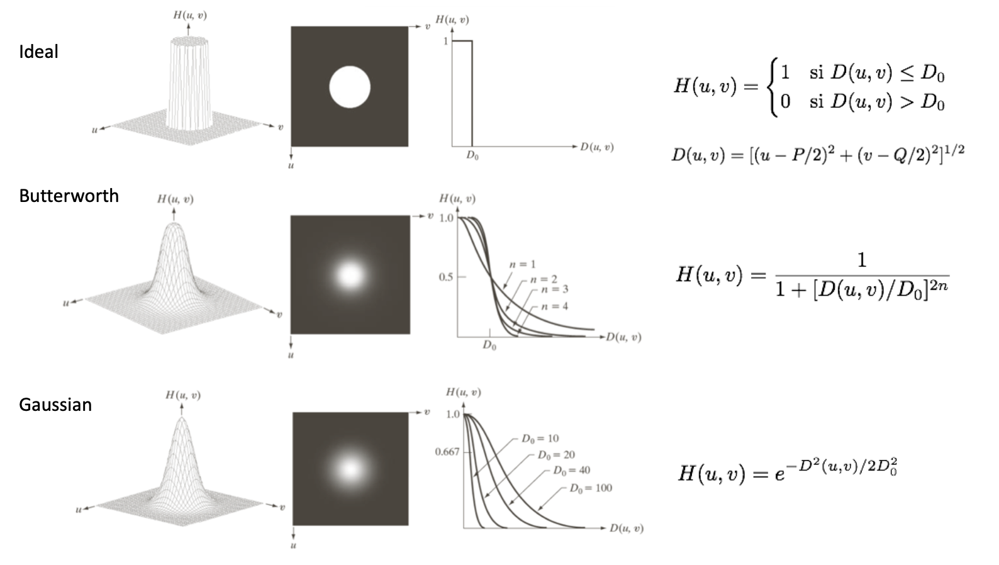

... El filtrado pasa alto corresponde a  $1-H(u,v)$

## Frecuencia de corte

In [8]:
Do = 50

## Funciones de filtrado

In [9]:
def distance(point1,point2):
    return np.sqrt((point1[0]-point2[0])**2 + (point1[1]-point2[1])**2)

def idealFilterLP(D0,imgShape):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            if distance((y,x),center) < D0:
                base[y,x] = 1
    return base

def idealFilterHP(D0,imgShape):
    base = np.ones(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            if distance((y,x),center) < D0:
                base[y,x] = 0
    return base

def butterworthLP(D0,imgShape,n):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = 1/(1+(distance((y,x),center)/D0)**(2*n))
    return base

def butterworthHP(D0,imgShape,n):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = 1-1/(1+(distance((y,x),center)/D0)**(2*n))
    return base

def gaussianLP(D0,imgShape):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = np.exp(((-distance((y,x),center)**2)/(2*(D0**2))))
    return base

def gaussianHP(D0,imgShape):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = 1 - np.exp(((-distance((y,x),center)**2)/(2*(D0**2))))
    return base





### Filtro ideal

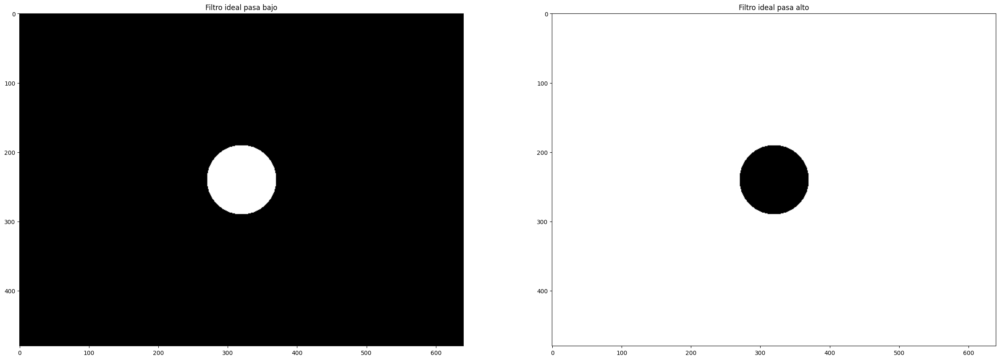

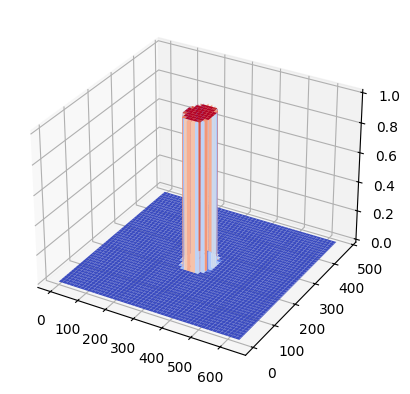

In [10]:
plt.figure(figsize=(30,15))

LowPass = idealFilterLP(Do,X.shape)
plt.subplot(121), plt.imshow(LowPass, "gray"), plt.title("Filtro ideal pasa bajo")

HighPass = idealFilterHP(Do,X.shape)
plt.subplot(122), plt.imshow(HighPass, "gray"), plt.title("Filtro ideal pasa alto")
surface_plot(LowPass, cmap=plt.cm.coolwarm)

plt.show()

### Filtro Butterworth

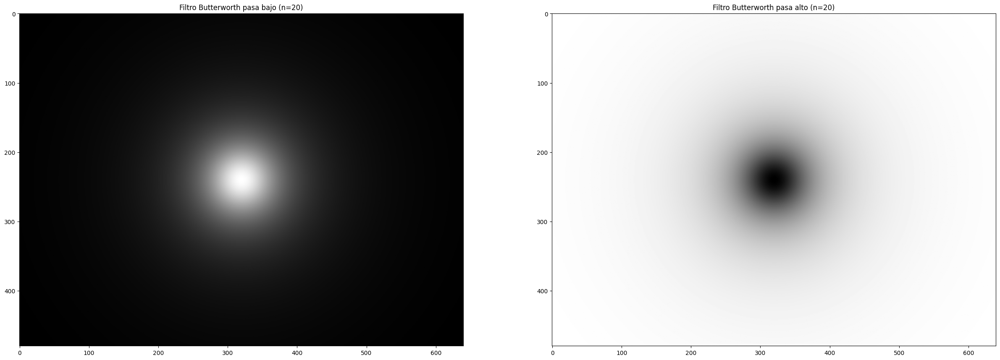

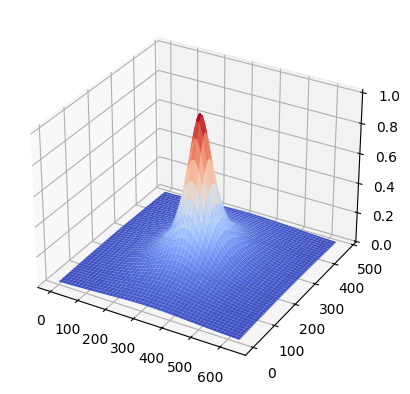

In [11]:
plt.figure(figsize=(30,15))

n = 1 # orden del filtro Butterworth

LowPass = butterworthLP(Do,X.shape,n)
plt.subplot(121), plt.imshow(LowPass, "gray"), plt.title("Filtro Butterworth pasa bajo (n=20)")

HighPass = butterworthHP(Do,X.shape,n)
plt.subplot(122), plt.imshow(HighPass, "gray"), plt.title("Filtro Butterworth pasa alto (n=20)")
surface_plot(LowPass, cmap=plt.cm.coolwarm)

plt.show()

### Filtro Gaussiano

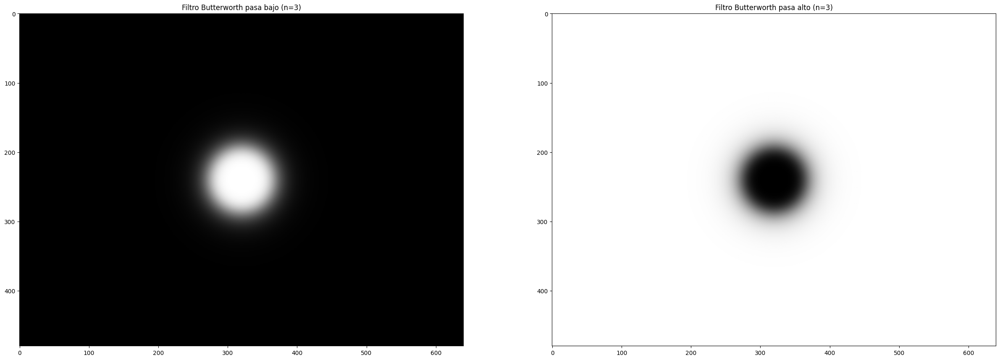

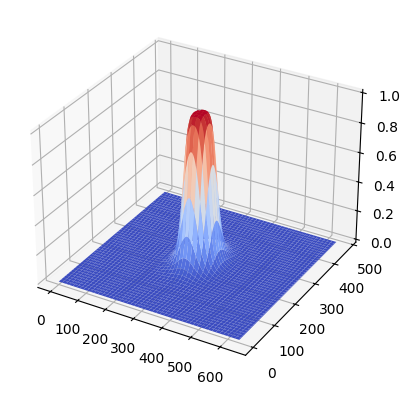

In [12]:
plt.figure(figsize=(30,15))

LowPass = butterworthLP(Do,X.shape,3)
plt.subplot(121), plt.imshow(LowPass, "gray"), plt.title("Filtro Butterworth pasa bajo (n=3)")

HighPass = butterworthHP(Do,X.shape,3)
plt.subplot(122), plt.imshow(HighPass, "gray"), plt.title("Filtro Butterworth pasa alto (n=3)")
surface_plot(LowPass, cmap=plt.cm.coolwarm)

plt.show()

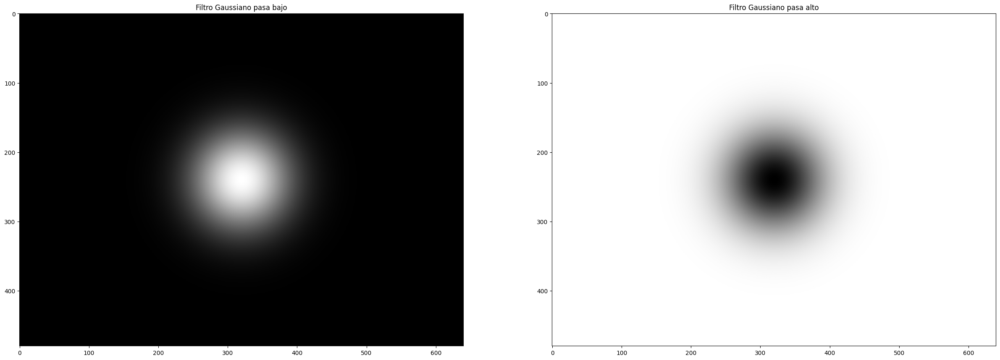

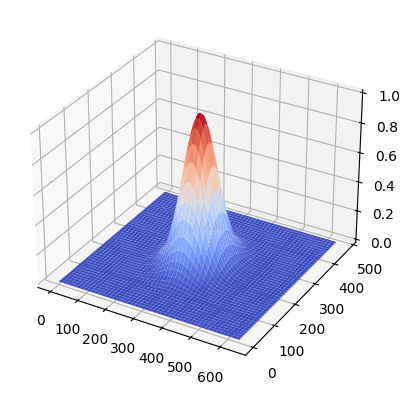

In [13]:
plt.figure(figsize=(30,15))

LowPass = gaussianLP(Do,X.shape)
plt.subplot(121), plt.imshow(LowPass, "gray"), plt.title("Filtro Gaussiano pasa bajo")

HighPass = gaussianHP(Do,X.shape)
plt.subplot(122), plt.imshow(HighPass, "gray"), plt.title("Filtro Gaussiano pasa alto")
surface_plot(LowPass, cmap=plt.cm.coolwarm)

plt.show()

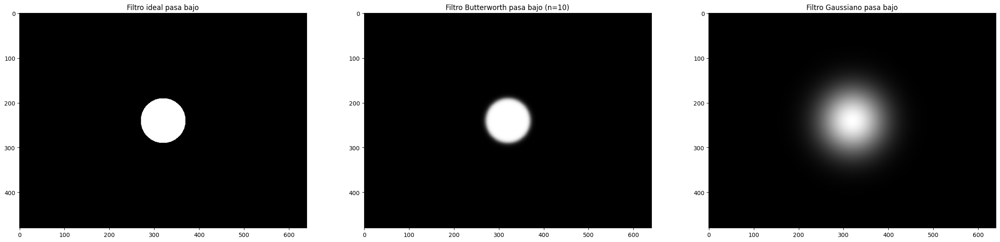

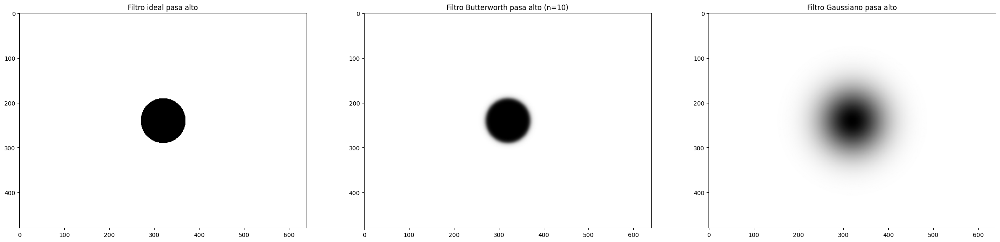

In [14]:
plt.figure(figsize=(30,15))

IdealLP = idealFilterLP(Do,X.shape)
plt.subplot(131), plt.imshow(IdealLP, "gray"), plt.title("Filtro ideal pasa bajo")

ButterLP = butterworthLP(Do,X.shape,10)
plt.subplot(132), plt.imshow(ButterLP, "gray"), plt.title("Filtro Butterworth pasa bajo (n=10)")

GaussianLP = gaussianLP(Do,X.shape)
plt.subplot(133), plt.imshow(GaussianLP, "gray"), plt.title("Filtro Gaussiano pasa bajo")

plt.figure(figsize=(30,15))
IdealHP = idealFilterHP(Do,X.shape)
plt.subplot(231), plt.imshow(IdealHP, "gray"), plt.title("Filtro ideal pasa alto")

ButterHP = butterworthHP(Do,X.shape,10)
plt.subplot(232), plt.imshow(ButterHP, "gray"), plt.title("Filtro Butterworth pasa alto (n=10)")

GaussianHP = gaussianHP(Do,X.shape)
plt.subplot(233), plt.imshow(GaussianHP, "gray"), plt.title("Filtro Gaussiano pasa alto")

plt.show()

## Ejemplos con filtros

### Filtrado ideal, Butterworth y Gaussiano

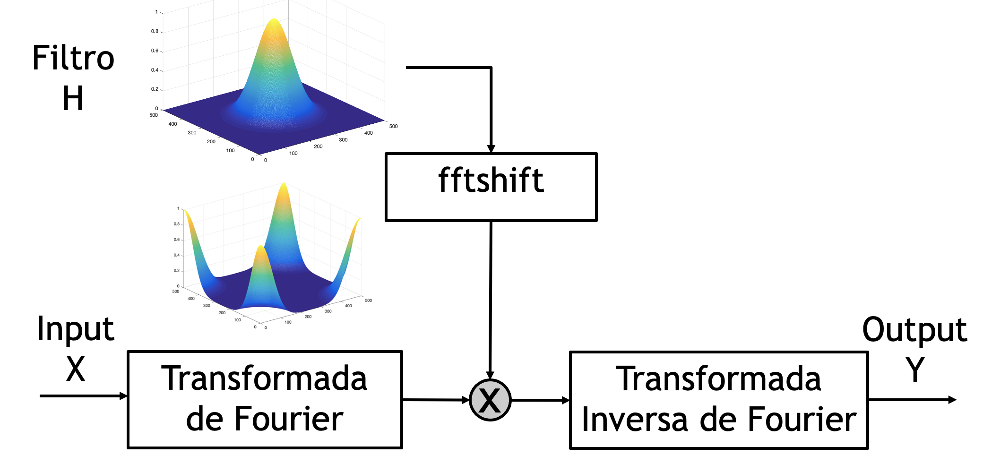

Gaussiano
pasa alto


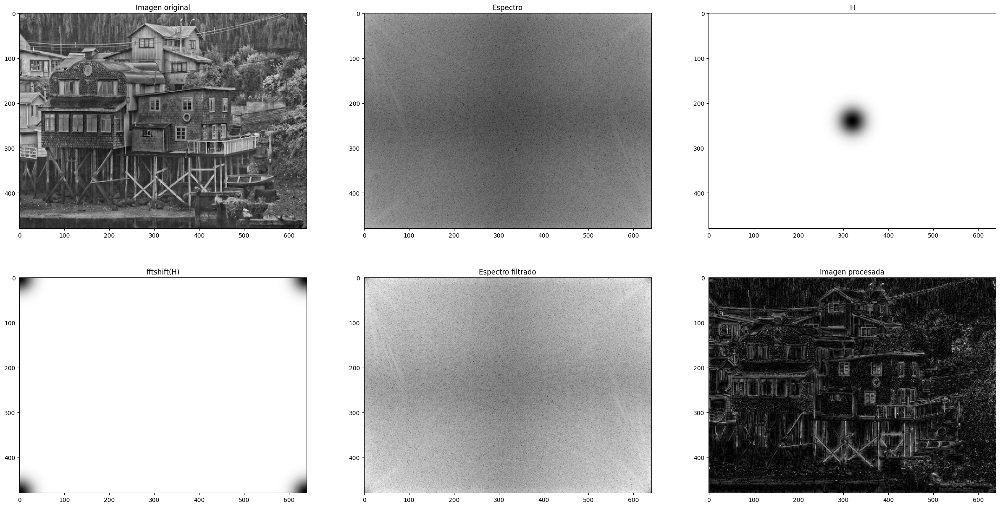

In [15]:
lp     = 2  # 1: pasa bajo  2: pasa alto
filtro = 3  # 1: ideal, 2: butterworth, 3: gaussiano
Do     = 20 # frecuencia de corte
n      = 4  # orden de Butterworth

if filtro == 1:
  H = idealFilterLP(Do,X.shape)
  print('Ideal')
elif filtro == 2:
  H = butterworthLP(Do,X.shape,n)
  print('Butterworth')
elif filtro == 3:
  H = gaussianLP(Do,X.shape)
  print('Gaussiano')

if lp==2:
  H = 1-H
  print('pasa alto')

plt.figure(figsize=(30,15))

plt.subplot(231), plt.imshow(X, "gray"), plt.title("Imagen original")

X_ft = fft2(X)
plt.subplot(232), plt.imshow(np.log(1+np.abs(X_ft)), "gray"), plt.title("Espectro")


plt.subplot(233), plt.imshow(H, "gray"), plt.title("H")

H_c = fftshift(H)
plt.subplot(234), plt.imshow(H_c, "gray"), plt.title("fftshift(H)")

Y_ft = X_ft * H_c
plt.subplot(235), plt.imshow(np.log(1+np.abs(Y_ft)), "gray"), plt.title("Espectro filtrado")

X_new = ifft2(Y_ft)
plt.subplot(236), plt.imshow(np.abs(X_new), "gray"), plt.title("Imagen procesada")

plt.show()

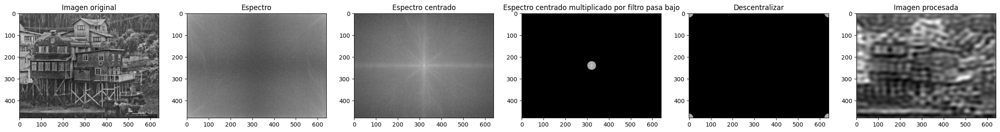

In [16]:
Do     = 20 # frecuencia de corte

plt.figure(figsize=(30,15))

img = X
plt.subplot(161), plt.imshow(img, "gray"), plt.title("Imagen original")

original = fft2(img)
plt.subplot(162), plt.imshow(np.log(1+np.abs(original)), "gray"), plt.title("Espectro")

center = fftshift(original)
plt.subplot(163), plt.imshow(np.log(1+np.abs(center)), "gray"), plt.title("Espectro centrado")

LowPassCenter = center * idealFilterLP(Do,img.shape)
plt.subplot(164), plt.imshow(np.log(1+np.abs(LowPassCenter)), "gray"), plt.title("Espectro centrado multiplicado por filtro pasa bajo")

LowPass = ifftshift(LowPassCenter)
plt.subplot(165), plt.imshow(np.log(1+np.abs(LowPass)), "gray"), plt.title("Descentralizar")

inverse_LowPass = ifft2(LowPass)
plt.subplot(166), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Imagen procesada")

plt.show()

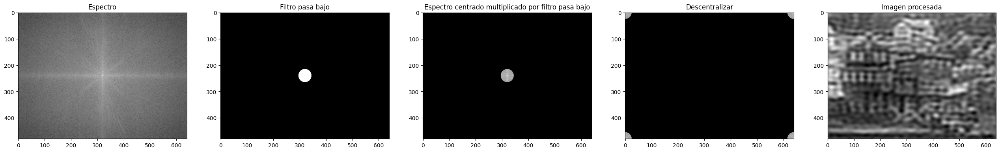

In [17]:
Do     = 25 # frecuencia de corte

img = X
original = fft2(img)
center = fftshift(original)

plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

plt.subplot(151), plt.imshow(np.log(1+np.abs(center)), "gray"), plt.title("Espectro")

LowPass = idealFilterLP(Do,img.shape)
plt.subplot(152), plt.imshow(np.abs(LowPass), "gray"), plt.title("Filtro pasa bajo")

LowPassCenter = center * idealFilterLP(Do,img.shape)
plt.subplot(153), plt.imshow(np.log(1+np.abs(LowPassCenter)), "gray"), plt.title("Espectro centrado multiplicado por filtro pasa bajo")

LowPass = ifftshift(LowPassCenter)
plt.subplot(154), plt.imshow(np.log(1+np.abs(LowPass)), "gray"), plt.title("Descentralizar")

inverse_LowPass = ifft2(LowPass)
plt.subplot(155), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Imagen procesada")

plt.show()

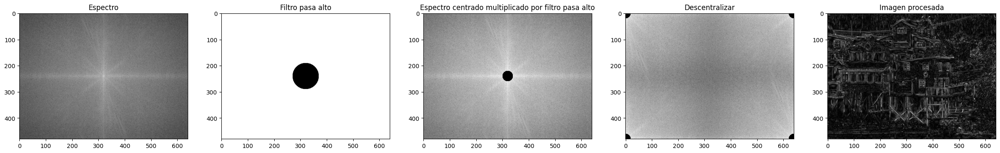

In [18]:
Do     = 20 # frecuencia de corte

img = X
original = fft2(img)
center = fftshift(original)

plt.figure(figsize=(30,15))

plt.subplot(151), plt.imshow(np.log(1+np.abs(center)), "gray"), plt.title("Espectro")

HighPass = idealFilterHP(50,img.shape)
plt.subplot(152), plt.imshow(np.abs(HighPass), "gray"), plt.title("Filtro pasa alto")

HighPassCenter = center * idealFilterHP(Do,img.shape)
plt.subplot(153), plt.imshow(np.log(1+np.abs(HighPassCenter)), "gray"), plt.title("Espectro centrado multiplicado por filtro pasa alto")

HighPass = ifftshift(HighPassCenter)
plt.subplot(154), plt.imshow(np.log(1+np.abs(HighPass)), "gray"), plt.title("Descentralizar")

inverse_HighPass = ifft2(HighPass)
plt.subplot(155), plt.imshow(np.abs(inverse_HighPass), "gray"), plt.title("Imagen procesada")

plt.show()

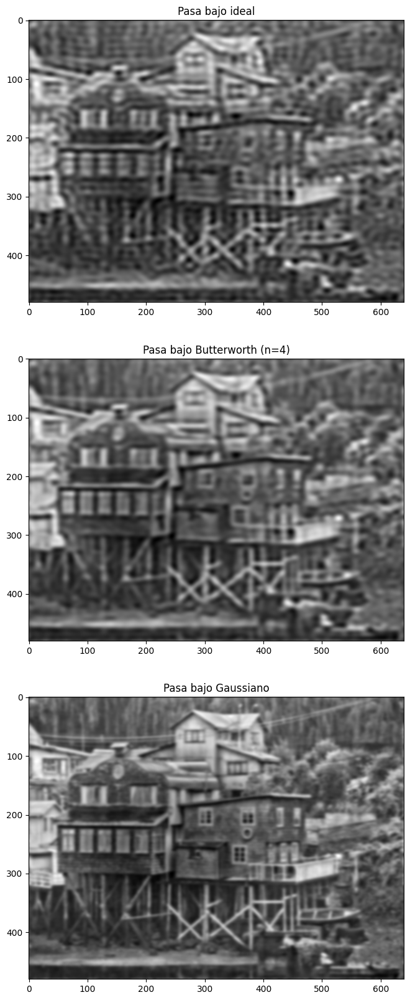

In [19]:
Do     = 40 # frecuencia de corte

img = X
original = fft2(img)
center = fftshift(original)

plt.figure(figsize=(40,20))

LowPassCenter = center * idealFilterLP(Do,img.shape)
LowPass = ifftshift(LowPassCenter)
inverse_LowPass = ifft2(LowPass)
plt.subplot(311), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Pasa bajo ideal")

LowPassCenter = center * butterworthLP(Do,img.shape,n)
LowPass = ifftshift(LowPassCenter)
inverse_LowPass = ifft2(LowPass)
plt.subplot(312), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Pasa bajo Butterworth (n="+str(n)+")")

LowPassCenter = center * gaussianLP(Do,img.shape)
LowPass = ifftshift(LowPassCenter)
inverse_LowPass = ifft2(LowPass)
plt.subplot(313), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Pasa bajo Gaussiano")

plt.show()

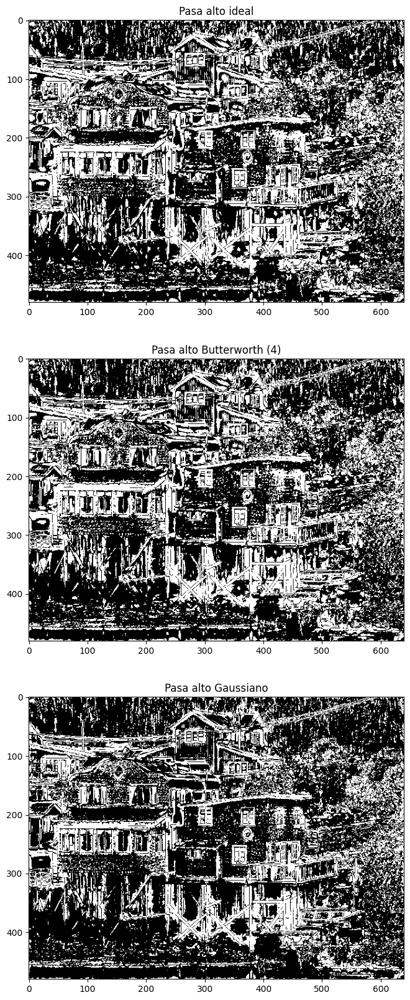

In [20]:
img = X
original = fft2(img)
center = fftshift(original)
Do = 20
th = 20
plt.figure(figsize=(40,20))

HighPassCenter = center * idealFilterHP(Do,img.shape)
HighPass = ifftshift(HighPassCenter)
inverse_HighPass = ifft2(HighPass)
plt.subplot(311), plt.imshow(np.abs(inverse_HighPass)>th, "gray"), plt.title("Pasa alto ideal")

HighPassCenter = center * butterworthHP(Do,img.shape,10)
HighPass = ifftshift(HighPassCenter)
inverse_HighPass = ifft2(HighPass)
plt.subplot(312), plt.imshow(np.abs(inverse_HighPass)>th, "gray"), plt.title("Pasa alto Butterworth ("+str(n)+")")

HighPassCenter = center * gaussianHP(Do,img.shape)
HighPass = ifftshift(HighPassCenter)
inverse_HighPass = ifft2(HighPass)
plt.subplot(313), plt.imshow(np.abs(inverse_HighPass)>th, "gray"), plt.title("Pasa alto Gaussiano")

plt.show()

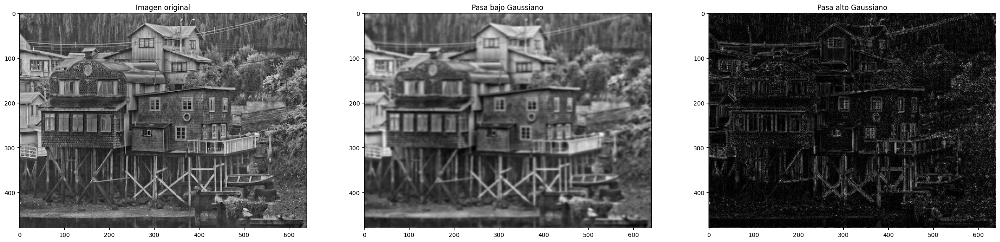

In [21]:
Do     = 50 # frecuencia de corte

img = X
original = fft2(img)
center = fftshift(original)

plt.figure(figsize=(30,15))

plt.subplot(131), plt.imshow(img, "gray"), plt.title("Imagen original")

LowPassCenter = center * gaussianLP(Do,img.shape)
LowPass = ifftshift(LowPassCenter)
inverse_LowPass = ifft2(LowPass)
plt.subplot(132), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Pasa bajo Gaussiano")

HighPassCenter = center * gaussianHP(Do,img.shape)
HighPass = ifftshift(HighPassCenter)
inverse_HighPass = ifft2(HighPass)
plt.subplot(133), plt.imshow(np.abs(inverse_HighPass), "gray"), plt.title("Pasa alto Gaussiano")

plt.show()

### Reducción de ruido

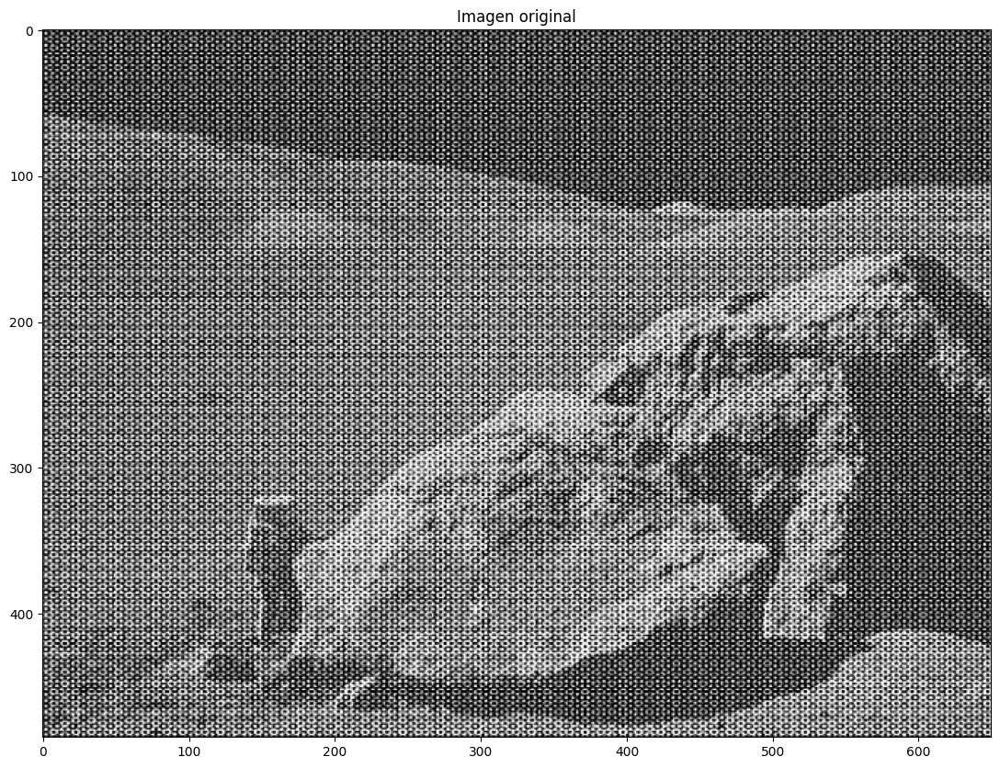

In [24]:
X = cv2.imread('moonlanding.png',0)/255.0
plt.figure(figsize=(20,10))
plt.imshow(X, plt.cm.gray)
plt.title('Imagen original')
plt.show()

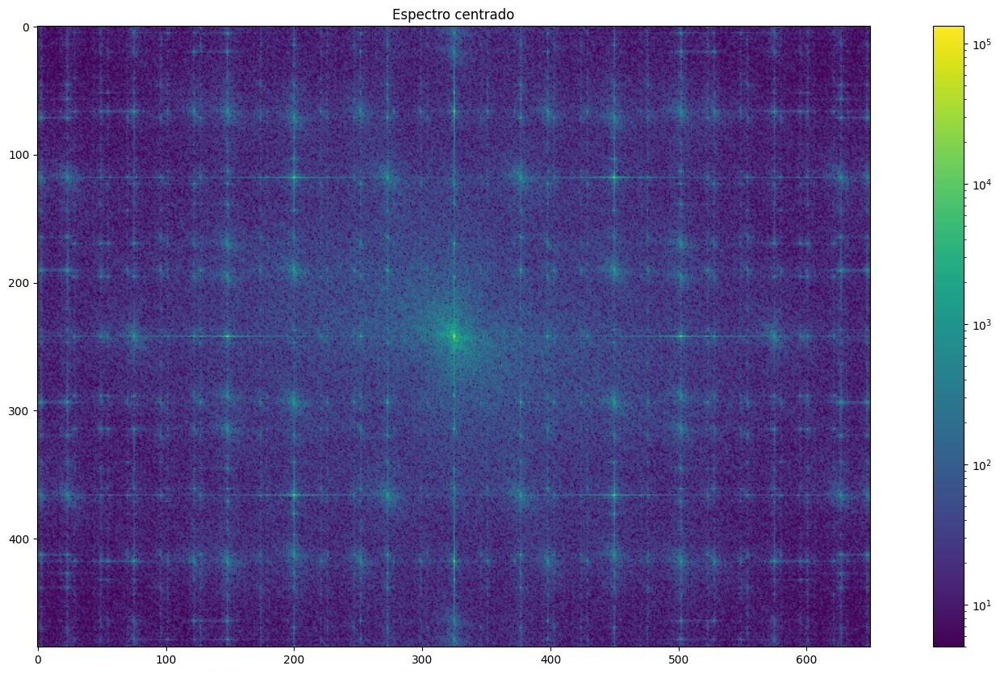

In [25]:
X_ft = fft2(X)
X_ftc = fftshift(X_ft)

plt.figure(figsize=(20,10))
plot_spectrum(X_ft)
plt.title('Espectro centrado')
plt.show()

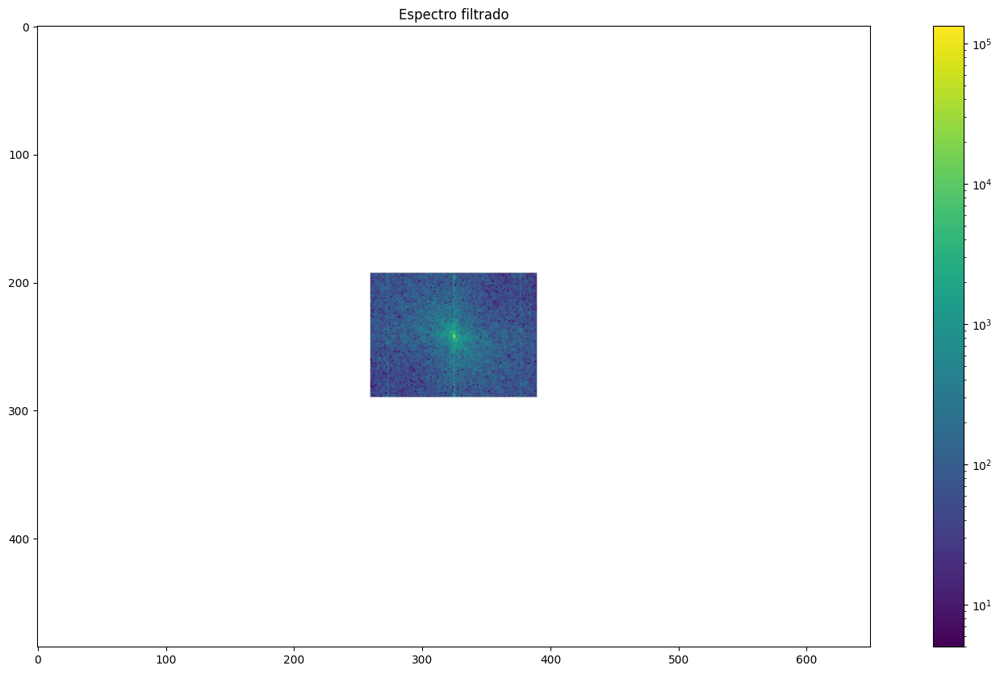

In [26]:
# En las siguientes líneas haremos una copia del espectro original y
# truncaremos los coeficientes.

# Definimos la fracción de coeficientes (en cada dirección) que conservamos
keep_fraction = 0.1

# Llamamos X_ft2 a una copia de la transformada original. Los arreglos de
# Numpy tienen un método copy para este propósito.
X_ft2 = X_ft.copy()

# Asignamos a r y c el número de filas y columnas del arreglo.
r, c = X_ft2.shape

# Ponemos en cero todas las filas con índices entre r*keep_fraction y
# r*(1-keep_fraction):
X_ft2[int(r*keep_fraction):int(r*(1-keep_fraction))] = 0

# De forma similar con las columnas:
X_ft2[:, int(c*keep_fraction):int(c*(1-keep_fraction))] = 0

plt.figure(figsize=(20,10))
plot_spectrum(X_ft2)
plt.title('Espectro filtrado')
plt.show()

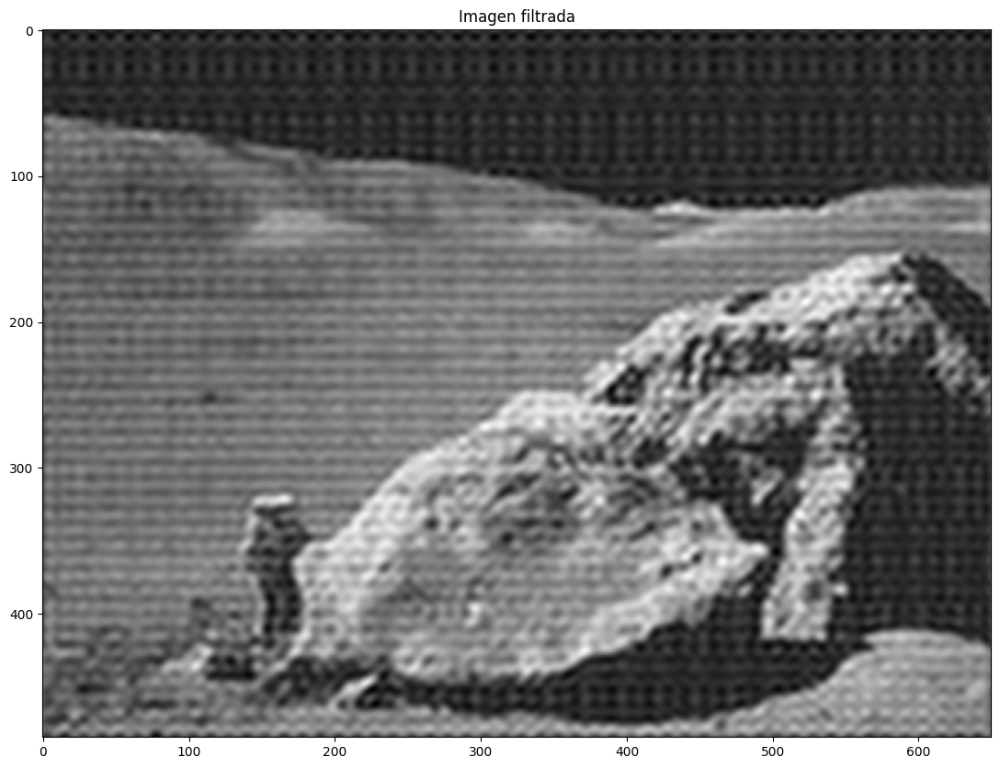

In [27]:
# Reconstruimos la imagen sin ruido a partir del espectro filtrado,
# conservando solo la parte real para mostrarla.
Y = ifft2(X_ft2).real

plt.figure(figsize=(20,10))
plt.imshow(Y, plt.cm.gray)
plt.title('Imagen filtrada')
plt.show()

In [28]:
Y = gaussian_filter(X,3)

Y_ft = fft2(Y)


plt.figure(figsize=(20,10))
plot_spectrum(X_ft)
plt.title('Espectro original')
plt.show()

plt.figure(figsize=(20,10))
plot_spectrum(Y_ft)
plt.title('Espectro filtrado')
plt.show()

plt.figure(figsize=(20,10))
plt.imshow(Y, plt.cm.gray)
plt.title('Imagen filtrada')

plt.show()
plt.figure(figsize=(20,10))
plt.imshow(X, plt.cm.gray)
plt.title('Imagen original')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

### Filtrado anti-aliasing

Es importante recordar que el filtro anti-aliasing es un filtro pasa bajo que se usa ANTES de muestrear la imagen, para eliminar las altas frecuencias de la imagen original. De esta forma, la imagen muestreada respeta el teorema de Nyquist, es decir, muestrear la imagen al menos al doble de la frecuencia máxima de la (nueva) imagen.

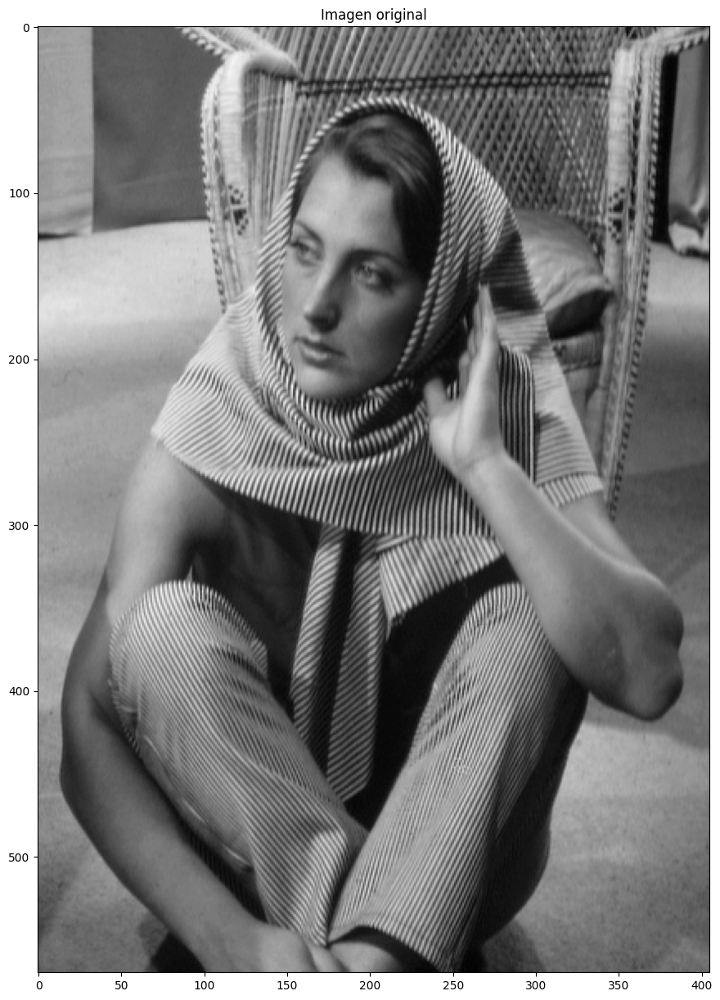

In [29]:
X = cv2.imread('barbara.png',0)
plt.figure(figsize=(30,15))
plt.imshow(X,cmap='gray')
plt.title("Imagen original")
plt.show()

In [30]:
# Submuestreo
def subsampling(X,s):
  (N,M) = X.shape
  N2 = int(N/s)
  M2 = int(M/s)

  Y = np.zeros((N2,M2))
  for i2 in range(N2):
    i = int(i2*s)
    for j2 in range(M2):
      j = int(j2*s)
      Y[i2,j2] = X[i,j]
  return Y


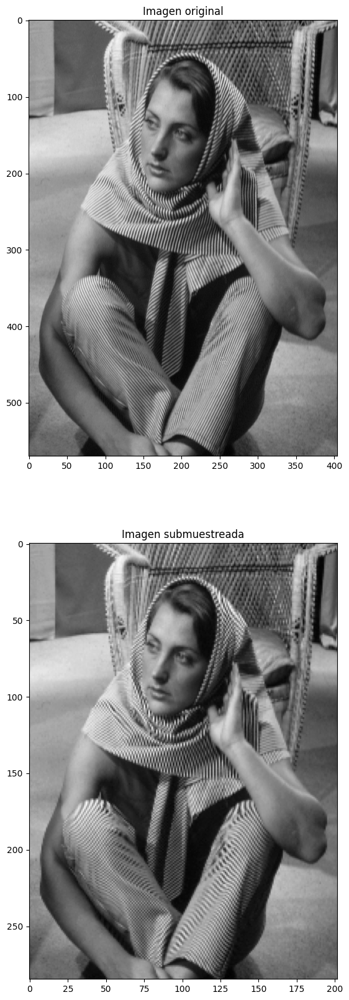

In [31]:
# Submuestreo sin filtrado anti-aliasing

m = 2 # submuestrear cada m píxeles
Y = subsampling(X,m)

plt.figure(figsize=(40,20))


plt.subplot(211),plt.imshow(np.abs(X), "gray"), plt.title("Imagen original")
plt.subplot(212),plt.imshow(np.abs(Y), "gray"), plt.title("Imagen submuestreada")

plt.show()

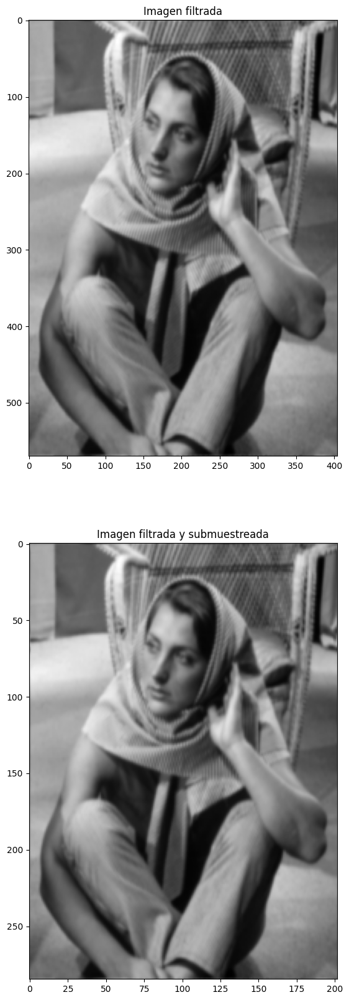

In [32]:
X_ft = fft2(X)
X_ftc = fftshift(X_ft)

Do = 50

plt.figure(figsize=(40,20))


Yo_ftc = X_ftc * gaussianLP(Do,X.shape)
Yo_ft = ifftshift(Yo_ftc)
Yo = ifft2(Yo_ft).real

Y  = subsampling(Yo,m)

plt.subplot(211),plt.imshow(np.abs(Yo), "gray"), plt.title("Imagen filtrada")
plt.subplot(212),plt.imshow(np.abs(Y), "gray"), plt.title("Imagen filtrada y submuestreada")

plt.show()

# Diseño de filtros en el dominio del espacio

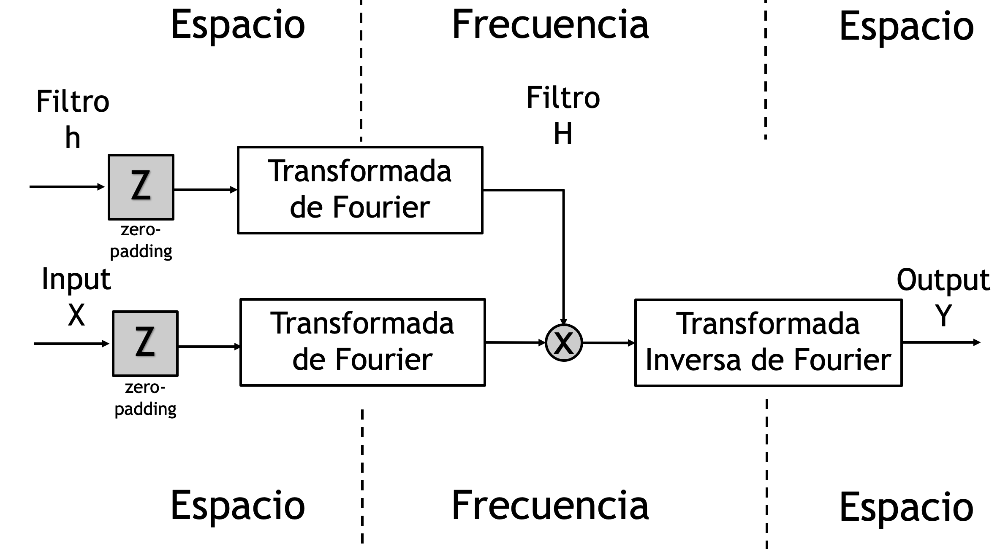

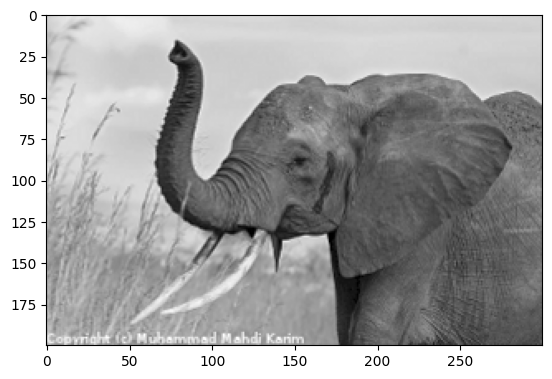

In [33]:
# leer imagen
X = cv2.imread('elephant.png', 0)/255.0
plt.figure()
plt.imshow(X,cmap='gray')
plt.show()

## Definición del filtro en el dominio del espacio

/tmp/ipykernel_3281/1199258398.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  bump /= np.trapz(bump) # normalizar la integral a 1


(30, 30)


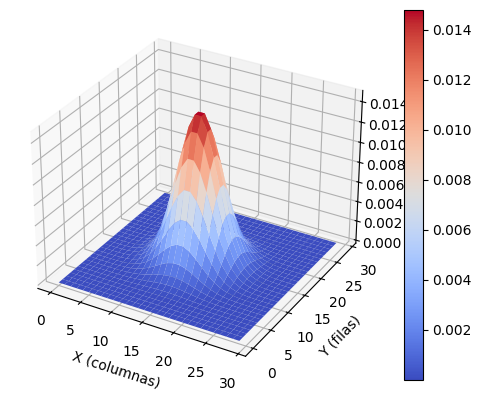

In [34]:
# Primero una Gaussiana 1-D
t = np.linspace(-10, 10, 30)
bump = np.exp(-0.1*t**2)
bump /= np.trapz(bump) # normalizar la integral a 1

# construir un kernel 2-D a partir de ella
h = bump[:, np.newaxis] * bump[np.newaxis, :]

print(h.shape)

(fig, ax, surf) = surface_plot(h, cmap=plt.cm.coolwarm)

fig.colorbar(surf)

ax.set_xlabel('X (columnas)')
ax.set_ylabel('Y (filas)')
ax.set_zlabel('Z (valores)')
plt.show()

## Implementación con zero-padding (relleno de ceros)

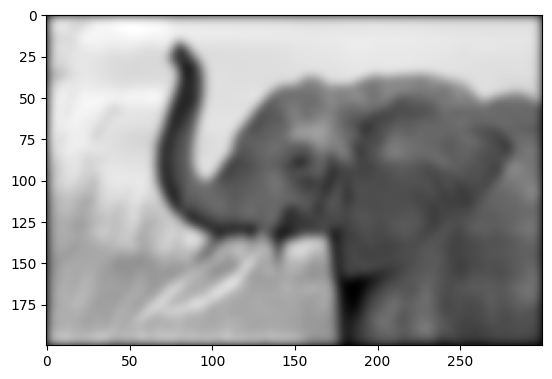

In [35]:
A = X.shape[0]
B = X.shape[1]
C = h.shape[0]
D = h.shape[1]
P = A+C-1
Q = B+D-1

h_ft = fft2(h, shape=(P,Q), axes=(0, 1))

# convolucionar
X_ft  = fft2(X, shape=(P,Q), axes=(0, 1))
X2_ft = h_ft * X_ft
Yo    = ifft2(X2_ft, axes=(0, 1)).real

# recortar los valores al rango
a = int(C/2)-1
b = int(D/2)-1
Y = np.clip(Yo[a:a+A,b:b+B], 0, 1)

# graficar la salida
plt.figure()
plt.imshow(Y,cmap='gray')
plt.show()

## Implementación con fftconvolve

(200, 300)


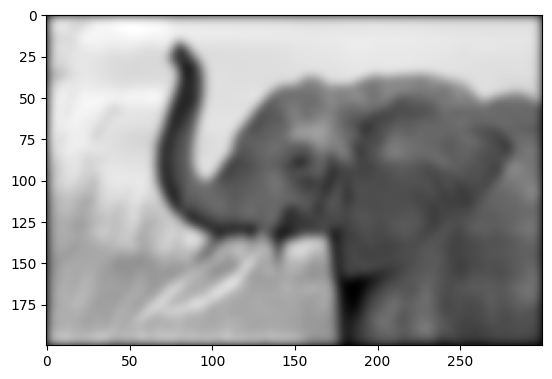

In [36]:
# El mismo resultado se obtiene con fftconvolve
# Notar que X y h están en el dominio del espacio.
# La función realiza el zero-padding, las transformadas de Fourier, la multiplicación de los espectros
# y la transformada inversa
Y = fftconvolve(X,h, mode='same')
plt.figure()
plt.imshow(Y,cmap='gray')
print(Y.shape)
plt.show()